# PEMS08F — residuals, backbone, and prior analysis

This notebook walks through everything we have for **PEMS08F** before training the diffusion model, in plain language:

1. **The residuals** — what is actually saved in the `.npz` files and what every number means.
2. **The backbone** — is our Graph WaveNet any good? We compare it to the published numbers.
3. **The sensor graph (Laplacian)** — is the graph healthy, and what do the eigenvalues mean.
4. **Gamma** — the one knob that controls spatial smoothness, and how it was chosen.
5. **Temporal structure** — how the error behaves across the 12 forecast steps.
6. **Stiffness and c0** — the numbers the diffusion schedule needs, and why some look alarming.
7. **Summary** — what is fine, what is broken, what to do next.

Quick facts for PEMS08F: **170 sensors**, units are **vehicles / 5 min (traffic flow)**, split is **60 / 20 / 20 (chronological)**, 12 forecast steps (5 min each, so up to 60 min ahead).

In [1]:
# setup: pick the dataset and make the src imports work
dataset = "pems08f"

import os, sys
while not os.path.exists("pyproject.toml"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.optimize import brentq

from src.data.adjacency import compute_normalized_laplacian, load_adjacency
from src.diffusion.prior import GAMMA_LOCKED
from src.utils import paths

seed = 0
print("dataset:", dataset, " gamma:", round(GAMMA_LOCKED[dataset], 4))

dataset: pems08f  gamma: 0.9239


## 1. The residuals — what is in the npz

The pipeline so far: the Graph WaveNet backbone takes the last hour of traffic and predicts the next hour (12 steps). For every window we store the **residual = what actually happened − what the model predicted**, in real-world units (mph or vehicles, *not* z-scored).

We saved three files per dataset — `train.npz`, `val.npz`, `test.npz` — each with these arrays:

| key | shape | what it is |
|---|---|---|
| `residuals` | (B, N, H) | truth − prediction, raw units. **this is the thing we model.** |
| `y_pred` | (B, N, H) | the backbone's forecast |
| `y_true` | (B, N, H) | the real future traffic — *optional*: newer files drop it to save ~⅓ space, since `y_true = y_pred + residuals` |
| `mask` | (B, N, H) | True where the data is real, False where it is missing |
| `mean`, `std` | scalars | the z-score stats used on the model input (not applied to the arrays above) |

Here **B** = number of windows, **N** = sensors, **H** = 12 forecast steps. Let's load it and look.

In [2]:
d = np.load(paths.residual_npz(dataset, "train", seed))
print("keys:", d.files)
for k in d.files:
    print(f"  {k:10s} shape={str(d[k].shape):16s} dtype={d[k].dtype}")

R = d["residuals"].astype(np.float64)
B, N, H = R.shape
print(f"\nB = {B} windows,  N = {N} sensors,  H = {H} steps")
print("scaler used on the input:  mean =", round(float(d['mean']), 3), " std =", round(float(d['std']), 3))

keys: ['residuals', 'y_pred', 'y_true', 'mask', 'mean', 'std']


  residuals  shape=(10691, 170, 12) dtype=float32


  y_pred     shape=(10691, 170, 12) dtype=float32
  y_true     shape=(10691, 170, 12) dtype=float32


  mask       shape=(10691, 170, 12) dtype=bool
  mean       shape=()               dtype=float32
  std        shape=()               dtype=float32



B = 10691 windows,  N = 170 sensors,  H = 12 steps
scaler used on the input:  mean = 229.646  std = 145.644


### one concrete window, so the numbers feel real

Below is a single window for sensor 0: the true future, the model's forecast, and the residual (the gap), at +5, +30, +60 minutes. Notice the residual is just `y_true − y_pred`, and it is in the same real units.

In [3]:
yp = d["y_pred"].astype(np.float64)
# y_true is optional in newer files; reconstruct it from y_pred + residual when missing
if "y_true" in d.files:
    yt = d["y_true"].astype(np.float64)
    print("(y_true was stored)")
else:
    yt = yp + R
    print("(y_true not stored - reconstructed as y_pred + residual)")

print("step      y_true   y_pred   residual")
for h in [0, 5, 11]:
    print(f"+{(h+1)*5:>2} min   {yt[0,0,h]:>7.2f}  {yp[0,0,h]:>7.2f}   {R[0,0,h]:>+7.2f}")

(y_true was stored)
step      y_true   y_pred   residual
+ 5 min     87.00    93.53     -6.53
+30 min     85.00    84.74     +0.26
+60 min     82.00    75.14     +6.86


### missing data

This dataset is treated as complete (matching the PEMS benchmark convention), so the mask is all True — nothing is dropped. We still carry the mask so the code path is the same for every dataset.

In [4]:
M = d["mask"].astype(bool)
print("fraction of entries that are real:", round(M.mean(), 4))
print("(1.0 means nothing is missing)")

fraction of entries that are real: 1.0
(1.0 means nothing is missing)


**What this means for PEMS08F:** every window is one hour of history → one hour of future for all 170 sensors. The residuals are in vehicles / 5 min (traffic flow). A positive residual means the road was *faster/busier* than the model predicted; negative means *slower/emptier*. This residual field is exactly what the diffusion model will learn to generate.

## 2. Is the backbone any good?

A residual model is only meaningful if the backbone forecast is sensible. The cleanest check: compute our forecast error per horizon and compare it to the **published Graph WaveNet** numbers.

Because `residual = truth − prediction`, the forecast error is just the average size of the residual: **MAE at step h = mean(|residual at step h|)** over the real entries. Let's compute it on the validation set and lay it next to the paper.

step    our val MAE   paper
+ 5 min      13.86          -
+10 min      15.05          -
+15 min      15.90          -
+20 min      16.62          -
+25 min      17.35          -
+30 min      18.02          -
+35 min      18.94          -
+40 min      19.43          -
+45 min      19.97          -
+50 min      20.48          -
+55 min      21.09          -
+60 min      21.96          -


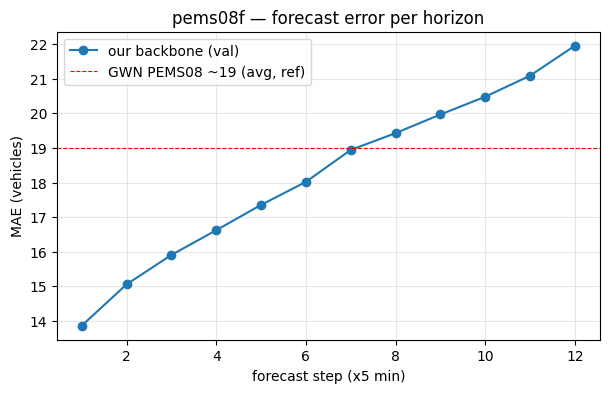

In [5]:
dv = np.load(paths.residual_npz(dataset, "val", seed))
Rv = np.abs(dv["residuals"].astype(np.float64))
Mv = dv["mask"].astype(bool)
mae = np.array([Rv[:, :, h][Mv[:, :, h]].mean() for h in range(H)])

bench = None  # GWN PEMS08 is usually reported as ~19 MAE averaged over all 12 steps (T-Graphormer)
print("step    our val MAE   paper")
for h in range(H):
    ref = f"{bench[h+1]:.2f}" if (bench and (h+1) in bench) else "-"
    print(f"+{(h+1)*5:>2} min     {mae[h]:>6.2f}      {ref:>5}")

plt.figure(figsize=(7,4))
plt.plot(range(1,H+1), mae, "o-", label="our backbone (val)")
plt.axhline(19.0, color='red', ls='--', lw=0.8, label='GWN PEMS08 ~19 (avg, ref)')
plt.xlabel("forecast step (x5 min)"); plt.ylabel("MAE (vehicles)")
plt.title(dataset + " — forecast error per horizon"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Verdict for PEMS08F:** h12 val MAE ~22 vehicles. Published Graph WaveNet on PEMS08 is ~19 averaged over all horizons; since h12 is the hardest step, ~22 at h12 is right in line.

The error grows with the horizon — predicting 60 minutes ahead is much harder than 5 minutes ahead — which is exactly what we expect. The shape of this curve also matters later: the residual variance grows the same way.

*Reference: Graph WaveNet on PEMS08 ≈ 19 MAE averaged over horizons (T-Graphormer, [arxiv.org/pdf/2501.13274](https://arxiv.org/pdf/2501.13274)); numbers vary 15–19 across papers because GWN was not the original PEMS08 method.*

## 3. The sensor graph and the Laplacian

The sensors form a graph: roads that are close/connected are neighbours. The **Laplacian** `L` is a matrix that measures, for any pattern of values across sensors, *how much neighbours disagree*. Its eigenvalues/eigenvectors are "patterns" ordered from smooth to jagged:

- **small eigenvalue (λ near 0)** = a smooth pattern, neighbours agree (the smoothest, λ=0, is "every sensor the same").
- **large eigenvalue** = a jagged pattern, neighbours swing in opposite directions.

Two health checks on the graph:
- **connectivity:** is the graph one connected piece? If a sensor has no edges, it is stranded and the prior can't share information with it.
- **the gap:** after the flat λ=0 pattern, how quickly do eigenvalues rise? A clear gap means well-defined structure.

In [6]:
A_raw = load_adjacency(dataset).astype(np.float64)
A = 0.5 * (A_raw + A_raw.T)              # make it symmetric
deg = (A != 0).sum(1) - (np.diag(A) != 0)
isolated = np.where(((A != 0).sum(1) - (np.diag(A) != 0)) == 0)[0]

adj = (A != 0).astype(int); np.fill_diagonal(adj, 0)
n_comp, label = connected_components(csr_matrix(adj), directed=False)

print("sensors:", A.shape[0])
print("median edges per sensor:", int(np.median(adj.sum(1))))
print("isolated sensors (no edges):", isolated.tolist())
print("connected pieces:", n_comp, "  (healthy = 1)")

sensors: 170
median edges per sensor: 2
isolated sensors (no edges): []
connected pieces: 1   (healthy = 1)


smallest 6 eigenvalues: [-0.      0.0105  0.0171  0.023   0.0284  0.0333]
lambda_1 = -1.32e-16  lambda_2 = 0.0105  lambda_max = 1.9816


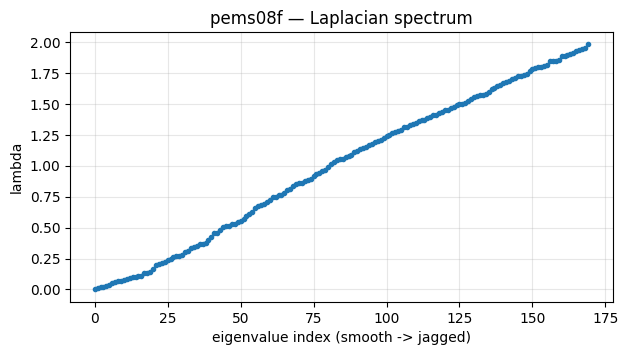

In [7]:
L = compute_normalized_laplacian(A_raw)
ev = np.linalg.eigvalsh(L)
print("smallest 6 eigenvalues:", np.round(ev[:6], 4))
print("lambda_1 =", f"{ev[0]:.2e}", " lambda_2 =", round(float(ev[1]),4), " lambda_max =", round(float(ev[-1]),4))

plt.figure(figsize=(7,3.5))
plt.plot(ev, ".")
plt.xlabel("eigenvalue index (smooth -> jagged)"); plt.ylabel("lambda")
plt.title(dataset + " — Laplacian spectrum"); plt.grid(alpha=0.3)
plt.show()

**What this means for PEMS08F:** The graph is one connected piece — the only dataset that passes the connectivity gate cleanly.

One subtle trap worth knowing: under this normalized Laplacian an *isolated* sensor shows up as an eigenvalue of exactly **1**, sitting in the middle of the spectrum — not as a second zero. So the eigenvalue list alone will *not* reveal a stranded sensor; only the connected-pieces count above catches it. That's why we check both.

## 4. Gamma — the spatial smoothness knob

The spatial part of the prior is `Sigma_S = (L + gamma*I)^(-1)`. In plain terms, it assigns a **variance to each graph pattern**: pattern with eigenvalue λ gets variance `1 / (λ + gamma)`.

- Smooth patterns (small λ) get **big** variance → the prior expects lots of smooth, neighbour-agreeing structure.
- Jagged patterns (big λ) get **small** variance → the prior discourages neighbours disagreeing.

**Gamma is the dial between two extremes:**
- `gamma -> 0`: huge gap between smooth and jagged → a very smooth prior.
- `gamma -> infinity`: every pattern gets the same variance → just independent noise, no graph at all.

So a **bigger gamma means a flatter, more "white-noise" prior**. Gamma isn't guessed — it's fit so the prior's roughness matches the residuals' actual roughness. Below we reproduce that fit (the energy-match method) and compare to the locked value.

residual roughness E_emp : 0.7876  (0 = perfectly smooth, ~1 = average)
gamma we refit from this : 0.9045
gamma locked in the code : 0.9239


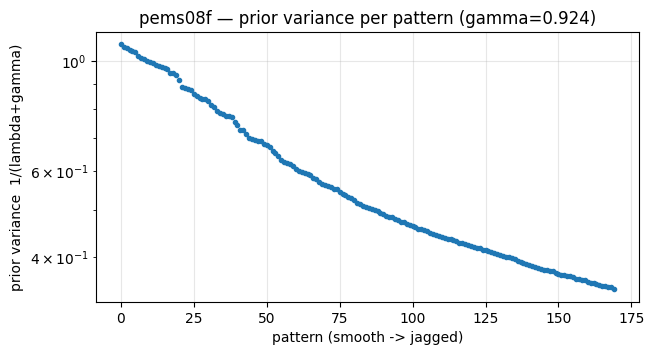

In [8]:
gamma = GAMMA_LOCKED[dataset]

# roughness of a pattern r across the graph = r^T L r / r^T r (0 = flat, ~1 = average jaggedness)
r = (R * M).transpose(0, 2, 1).reshape(-1, N)     # each (window, step) is one spatial pattern
E_emp = np.einsum("sn,nm,sm->", r, L, r) / (r * r).sum()

def prior_roughness(g):                            # what the prior expects, as a function of gamma
    mu = 1.0 / (ev + g)
    return (ev * mu).sum() / mu.sum()

gamma_fit = brentq(lambda g: prior_roughness(g) - E_emp, 1e-6, 1e4)
print("residual roughness E_emp :", round(E_emp, 4), " (0 = perfectly smooth, ~1 = average)")
print("gamma we refit from this :", round(gamma_fit, 4))
print("gamma locked in the code :", round(gamma, 4))

# show the variance each pattern gets under the locked gamma
plt.figure(figsize=(7,3.5))
plt.semilogy(1.0/(ev+gamma), ".")
plt.xlabel("pattern (smooth -> jagged)"); plt.ylabel("prior variance  1/(lambda+gamma)")
plt.title(dataset + f" — prior variance per pattern (gamma={round(gamma,3)})"); plt.grid(alpha=0.3)
plt.show()

**What this means for PEMS08F:** Largest gamma of the three (~0.92): PEMS08F residuals are the least spatially smooth, so the prior is pushed almost to plain independent noise.

Notice `E_emp` is fairly high (residuals are not very smooth), which is why this is honestly a *smoothness* prior that only partly fits the data — a known limitation we live with, and the diffusion noise schedule is meant to make up the difference. The refit value lands close to the locked one, confirming the locked number is right *for the current graph*. (If we fix the isolated sensors, the graph changes and this must be refit.)

## 5. Temporal structure — how error behaves across the 12 steps

The temporal part of the prior, `Sigma_T`, is a 12x12 matrix built from two pieces:

- **D_H** — the variance of the residual at each step (how big the error typically is at +5 min, +10 min, ...).
- **R_H** — the correlation between steps (if the model is too high at +5 min, is it also too high at +10 min?).

Two things to look at, and both turn out to be where our trouble is.

step   D_H (MAD)   true var   ratio
+ 5 min   162.4508  495.9894    3.1x
+30 min   256.2612  838.5391    3.3x
+60 min   378.9451  1193.2382    3.1x


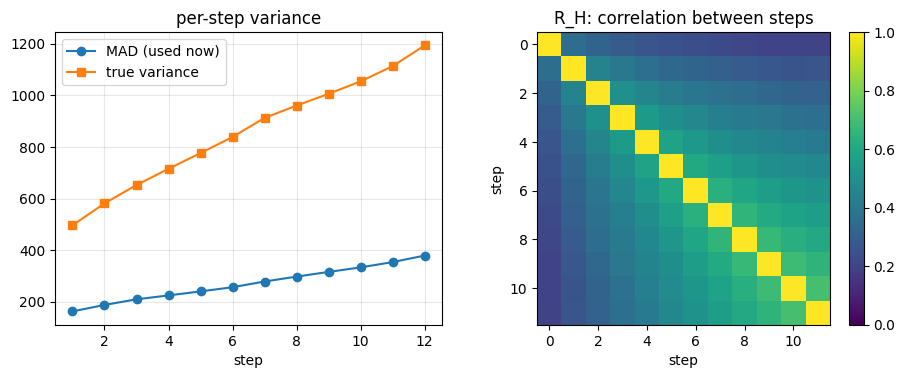

In [9]:
flat = R.reshape(B * N, H); keep = M.reshape(B * N, H).all(1); Rk = flat[keep]

# two ways to measure per-step variance:
mad = np.median(np.abs(Rk - np.median(Rk, 0)), 0)
D_H_mad = (1.4826 * mad) ** 2          # robust (MAD) — what the prior currently uses
D_H_ms  = (Rk ** 2).mean(0)            # plain mean of squares — the actual variance
R_H = np.corrcoef(Rk.T)                # step-to-step correlation

print("step   D_H (MAD)   true var   ratio")
for h in [0, 5, 11]:
    print(f"+{(h+1)*5:>2} min   {D_H_mad[h]:>8.4f}  {D_H_ms[h]:>8.4f}  {D_H_ms[h]/D_H_mad[h]:>5.1f}x")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(1,H+1), D_H_mad, "o-", label="MAD (used now)")
ax[0].plot(range(1,H+1), D_H_ms, "s-", label="true variance")
ax[0].set_title("per-step variance"); ax[0].set_xlabel("step"); ax[0].legend(); ax[0].grid(alpha=0.3)
im = ax[1].imshow(R_H, vmin=0, vmax=1, cmap="viridis")
ax[1].set_title("R_H: correlation between steps"); ax[1].set_xlabel("step"); ax[1].set_ylabel("step")
fig.colorbar(im, ax=ax[1]); plt.show()

**What this means for PEMS08F:** two problems show up here.

1. **The variance is measured with MAD, which throws away the big errors.** Traffic residuals have heavy tails (incidents, sudden jams). MAD ignores those, so it reports a variance several times too small — and the gap *grows* with the horizon (see the ratio column). The "true variance" curve climbs much faster than the MAD curve. The prior is being scaled by the wrong, flattened curve.

2. **The correlation matrix `R_H` is strong** — neighbouring steps are highly correlated (the bright off-diagonal in the heatmap). A strongly correlated matrix is nearly singular, and that is what makes the next section's stiffness blow up.

Also note an inconsistency: `D_H` is robust (MAD) but `R_H` is ordinary (Pearson) correlation. Mixing the two gives a `Sigma_T` that is neither cleanly robust nor cleanly empirical.

## 6. Stiffness and c0 — and why they look scary

The diffusion model uses the prior's **precision** (inverse variance) per mode. Combining space and time, each mode (graph-pattern k, step h) has precision:

`theta[k,h] = (lambda_k + gamma) / mu_h`     where `mu_h` are the eigenvalues of `Sigma_T`.

- **theta small** = a high-variance, slow-to-settle mode → needs a long diffusion time.
- **theta big** = a low-variance, fast mode.

Two numbers come out of this:
- **stiffness = theta_max / theta_min** — the ratio of fastest to slowest mode. Big stiffness = the SDE has to cover a huge range of timescales at once.
- **c0 = 5 / theta_min** — sets how long the diffusion has to run so even the slowest mode settles.

The key trick: stiffness **factorises** into a spatial part and a temporal part, so we can see exactly where it comes from.

In [10]:
mu = np.clip(np.linalg.eigvalsh((np.sqrt(D_H_mad)[:,None]*R_H)*np.sqrt(D_H_mad)[None,:]), 1e-12, None)
lam_max = ev[-1]
theta_min = gamma / mu.max()
theta_max = (lam_max + gamma) / mu.min()

spatial = (lam_max + gamma) / gamma        # what gamma controls
temporal = mu.max() / mu.min()             # condition of Sigma_T
condRH = np.linalg.eigvalsh(R_H); condRH = condRH.max() / condRH.min()

print("stiffness (total) :", round(spatial * temporal, 1))
print("   spatial part   :", round(spatial, 1), " (gamma's job - this is fine)")
print("   temporal part  :", round(temporal, 1), " (condition of Sigma_T - the problem)")
print("   of which R_H    :", round(condRH, 1), " (the correlation matrix alone)")
print("c0 = 5/theta_min  :", round(5.0/theta_min, 2))

# what a small 'gamma for time' (shrink R_H toward identity) would do
print("\nif we shrink R_H toward independence (a temporal regulariser):")
for a in [0.0, 0.05, 0.1, 0.2]:
    RHs = (1-a)*R_H + a*np.eye(H)
    m = np.clip(np.linalg.eigvalsh((np.sqrt(D_H_mad)[:,None]*RHs)*np.sqrt(D_H_mad)[None,:]), 1e-12, None)
    print(f"  shrink={a:<4}  temporal stiffness = {m.max()/m.min():>7.1f}")

stiffness (total) : 55.6
   spatial part   : 3.1  (gamma's job - this is fine)
   temporal part  : 17.7  (condition of Sigma_T - the problem)
   of which R_H    : 20.7  (the correlation matrix alone)
c0 = 5/theta_min  : 9265.95

if we shrink R_H toward independence (a temporal regulariser):
  shrink=0.0   temporal stiffness =    17.7
  shrink=0.05  temporal stiffness =    15.7
  shrink=0.1   temporal stiffness =    14.1
  shrink=0.2   temporal stiffness =    11.8


**What this means for PEMS08F:** Stiffness ~56, the lowest of the three. Still mostly temporal, but the graph here is the best behaved.

The decomposition is the whole story: the **spatial part (everything gamma controls) is small and healthy.** The stiffness comes almost entirely from the **temporal correlation matrix `R_H`** being nearly singular. The little experiment at the bottom shows that nudging `R_H` toward independence collapses the stiffness fast.

So we are **missing a temporal regulariser**. We carefully regularise space with gamma, but we drop the raw empirical `R_H` straight in with nothing taming it. The earlier (archived) approach used a parametric AR model for time, which is naturally well-behaved; the rewrite swapped to the raw matrix and inherited this problem.

## 7. Summary for PEMS08F

- **Residuals:** 170 sensors x 12 steps per window, in vehicles / 5 min (traffic flow), stored as truth − prediction. Treated as complete (no missing data).
- **Backbone:** h12 val MAE ~22 vehicles. Published Graph WaveNet on PEMS08 is ~19 averaged over all horizons; since h12 is the hardest step, ~22 at h12 is right in line.
- **Graph:** The graph is one connected piece — the only dataset that passes the connectivity gate cleanly.
- **Gamma:** Largest gamma of the three (~0.92): PEMS08F residuals are the least spatially smooth, so the prior is pushed almost to plain independent noise.
- **Stiffness / temporal:** Stiffness ~56, the lowest of the three. Still mostly temporal, but the graph here is the best behaved.

**Two things to fix before diffusion (shared across datasets):**
1. **Temporal scale** — replace the MAD variance with the real variance (the MAD version is several times too small and gets worse with horizon), and make `D_H` and `R_H` consistent.
2. **Temporal regulariser** — add a "gamma for time" (shrink `R_H`, or use a parametric AR/Matern kernel) so `Sigma_T` isn't near-singular. This is what brings the stiffness down to a sane range.

Neither needs re-running the backbone or re-extracting residuals — both are just changes to how `Sigma_T` is fit.